# Libraries

In [12]:
from MultiLayerNet import *

# Tunning Parameters

In [13]:
N = 500

# Functions

In [14]:
def f(x):
    y=np.sin(x)
    return y 

def df(x):
    dy = np.cos(x)
    return dy

In [15]:
def mygrad(y, x):
    dydx = grad(y, x, torch.ones(x.size()[0], 1, device=dev),
                create_graph=True, retain_graph=True)[0]
    return dydx

# Train Neural Network

# Load Model

In [16]:
# Set Neural Network
layers = [1,30,30,30,1]
model = MultiLayerNet(layers, init=True)
model.to(dev)
start_time = time.time()

model.load_state_dict(torch.load('./output/Case1/model.pt', map_location=torch.device(dev)))
model.eval()

Constructor: Init Network!


MultiLayerNet(
  (activation): Tanh()
  (linears): ModuleList(
    (0): Linear(in_features=1, out_features=30, bias=True)
    (1-2): 2 x Linear(in_features=30, out_features=30, bias=True)
    (3): Linear(in_features=30, out_features=1, bias=True)
  )
)

In [17]:
x_test = torch.linspace(0,2*np.pi,N).view(-1,1)
x_test.requires_grad_(True)

y_pred = model(x_test)
dy_pred = mygrad(y_pred, x_test)

x_test = x_test.detach().cpu().numpy()
y_real = f(x_test)
dy_real = df(x_test)

y_pred = y_pred.detach().cpu().numpy()
dy_pred = dy_pred.detach().cpu().numpy()

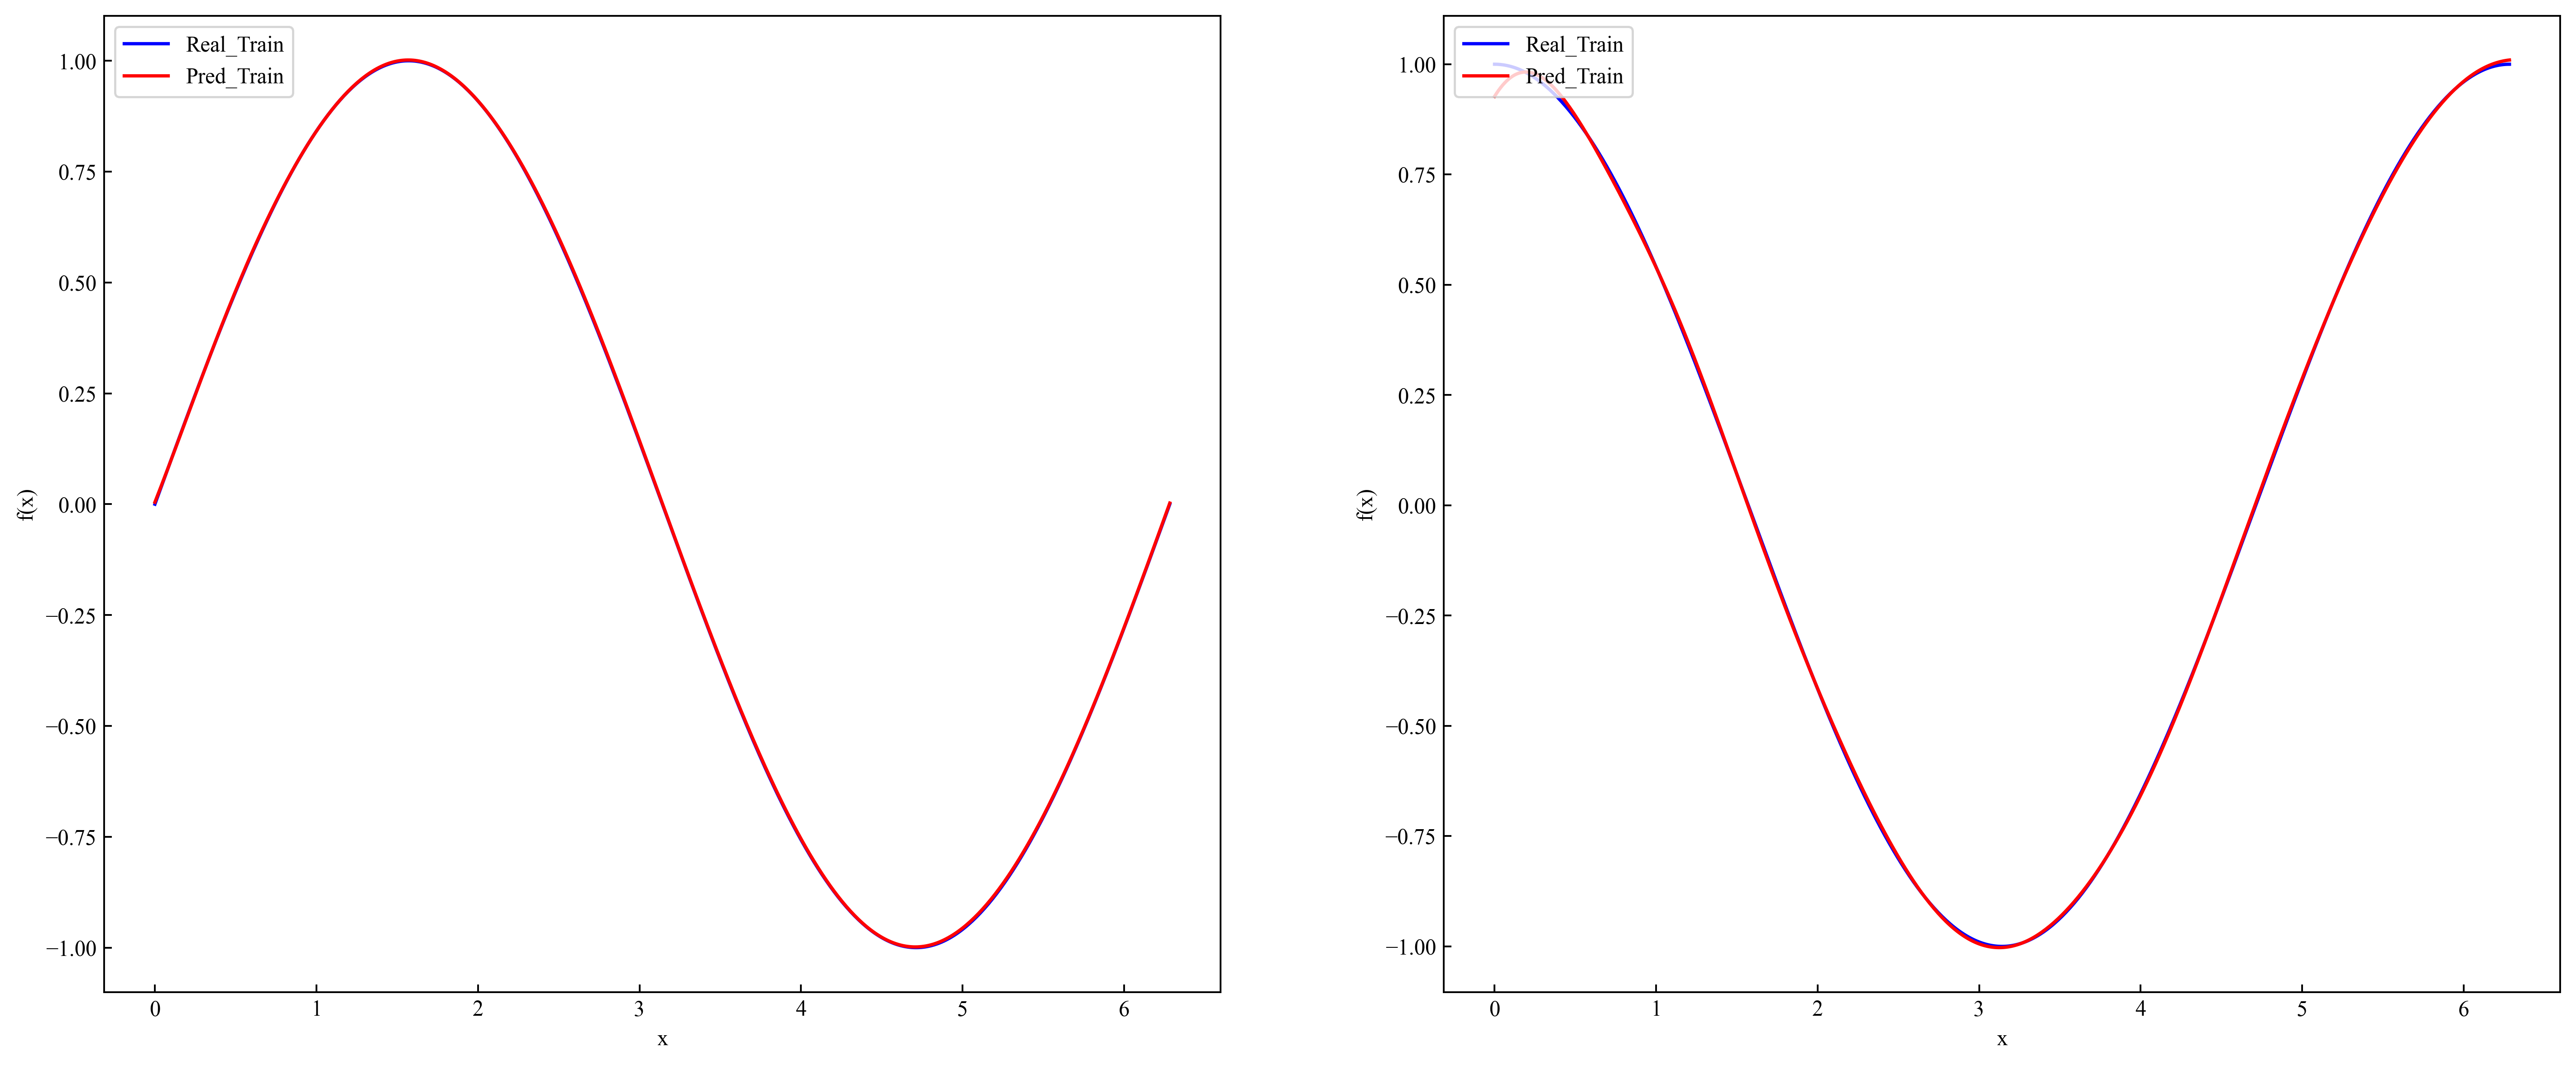

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
ax[0].plot(x_test,y_real,color='blue',label='Real_Train')
ax[0].plot(x_test,y_pred,color='red',label='Pred_Train')
ax[0].set_xlabel('x',color='black')
ax[0].set_ylabel('f(x)',color='black')
ax[0].tick_params(axis='y', color='black')
ax[0].legend(loc = 'upper left')

ax[1].plot(x_test,dy_real,color='blue',label='Real_Train')
ax[1].plot(x_test,dy_pred,color='red',label='Pred_Train')
ax[1].set_xlabel('x',color='black')
ax[1].set_ylabel('f(x)',color='black')
ax[1].tick_params(axis='y', color='black')
ax[1].legend(loc = 'upper left')

In [19]:
print('MSE for f(x):', np.mean(np.square(y_real-y_pred)))
print('MSE for df(x):', np.mean(np.square(dy_real-dy_pred)))

MSE for f(x): 3.5692092e-06
MSE for df(x): 6.5958375e-05
